# Математички методи за машинско учење 2025/26
## Домаћи задатак број 1

<div class="alert alert-block alert-danger">
<b>Име и презиме студента:</b> Jovan Paunović

<b>Број индекса:</b> 2122
    
</div>    

<div class="alert alert-block alert-info">
<b>Упутство за израду и предају домаћег задатака: </b> 
    
    1. Пре почетка израде промените име датотеке у 01Domaci_Ime_Prezime. (убаците своје име и презиме) 
    2. Попуните ћелију испод наслова одговарајућим подацима. 
    1. Употреба ћирилице није обавезна за предају домаћег задатка.
    4. За решавање задатака, уколико је потребно, отворите испод текста задатка додатне ћелије за уписивање текстуалног одговора (Markdown) или програмског кода (Code).
    1. Сва израчунавања, уколико је потребно, вршити у Python-у.
    5. Након завршетка израде решења домаћег Notebook документ сачувати у pdf формату и проследити га наставнику. То можете да урадите или кроз Teams или на мејл адресу jovana.dzunic@elfak.ni.ac.rs

</div> 

In [1]:
import numpy as np
import numpy.random as rndm
import matplotlib as mplb
import matplotlib.pyplot as plt
from timeit import default_timer as timer

**Задатак 1. а)** Креиран је низ од 100000 елемената bool вредности. Користећи функционалности низова (без Python петљи) пребројати број појављивања `[False, True]` узастопних елемената у задатом распореду.

(5 поена)

**Пример** Ако је генерисан низ `[False,  True,  True,  True, False,  True, False, False]` он садржи два пара узастопних елемената са задатим распоредом вредности `[False, True]`. Парови почињу индексима $0$ и $4.$

In [2]:
niz_bool=rndm.choice([False, True], 100000)

In [3]:
count = np.sum((~niz_bool[:-1]) & (niz_bool[1:]))
count

np.int64(24990)

<div class="alert alert-block alert-info">
<b>5/5 поена </b> 
</div>

***

**б)** Направити специјалну операцију множења две матрице димензија $5\times5.$ У двема матрицама се множе парови елемената на означеним (затамњеним) позицијама са слике, а затиме се добијени производи саберу. Позиције елемената који учествују у операцији означени су сивом бојом.

<div>
   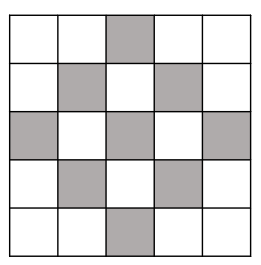  
</div>

- Решење мора бити векторизовано (без Python петљи).
- Код мора бити скалабилан. Другим речима да може лако да се преведе на случај матрице произвољне непарне димензије. Скалиран проблем на матрицу $7\times7$ дат је наредном сликом. 
<div>
   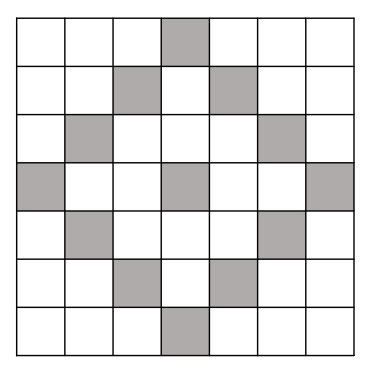  
</div>

(5 поена)

In [4]:
def multiply_matrices(A, B):
    n = A.shape[0]
    c = n // 2

    indices = np.arange(n)

    # racunaju se apsolutne udaljenosti od centra
    di = np.abs(indices.reshape(n, 1) - c)
    dj = np.abs(indices.reshape(1, n) - c)

    # vrsi se broadcasting i dobija se matrica koja sadrzi 
    # Manhattan udaljenosti svakog elementa od centra
    dist = di + dj

    mask = (dist == c) # okolna polja
    mask[c, c] = True # centar

    return np.sum(A[mask] * B[mask])

<div class="alert alert-block alert-info">
<b>5/5 поена </b> 
</div>

***

**Задатак 3.** Користећи `numpy`, `matplotlib` (или сродне библиотеке за цртање) и дефиниције значајних и сигурних цифара, решити следеће захтеве.

1.  **Имплементација функције:**
    Написати Python функцију `analiza_preciznosti(x_true, x_approx)` 
    *   **Улаз:** Функција мора бити написана тако да прихвата **NumPy низове** (векторе) као и појединачне скаларе.
    *   **Излаз:** Функција треба да врати две вредности (или два низа, ако је улаз био низ):
        1.  Број значајних цифара апроксимације (конверзијом у научну нотацију). *Напомена: За рад са низовима стрингова можете користити `np.vectorize`.*
        2.  Број сигурних цифара (користећи дату логаритамску формулу **без експлицитних петљи** за рачунање грешке).
    
(10 поена)    

In [5]:
def odredi_znacajne_cifre(x): # x je skalar
    if x == 0:
        return 1

    s = np.format_float_scientific(x)
    mantisa = s.split('e')[0].replace('.', '').lstrip('-')
    return len(mantisa)
     
def analiza_preciznosti(x_true, x_approx):
    if isinstance(x_approx, np.ndarray):
        vec_zc = np.vectorize(odredi_znacajne_cifre)
        znacajne_cifre = vec_zc(x_approx)
    else:
        znacajne_cifre = odredi_znacajne_cifre(x_approx)

    relativna_greska = np.abs(x_approx - x_true) / np.abs(x_true)
    sigurne_cifre = -np.log10(relativna_greska)

    return znacajne_cifre, sigurne_cifre

<div class="alert alert-block alert-info">
<b>10/10 поена </b> 
</div>

2.  **Појединачни тест:**
    Применити функцију на пар: $x_{tacno} = 8.779901$, $x_{aprox} = 8.8$. Исписати резултате.
    
(5 поена)    

In [6]:
zc, sc = analiza_preciznosti(8.779901, 8.8)
print(zc)
print(sc)

2
2.6403151687438076


<div class="alert alert-block alert-info">
<b>5/5 поена </b> 
</div>

3.  **Статистичка и визуелна анализа (Monte Carlo симулација):**
    У пракси (нпр. код машинског учења), подаци често имају различите опсеге вредности, што утиче на релативну грешку при фиксном заокруживању.
    *   Користећи `numpy.random` (или `rndm`), генерисати низ од $10.000$ случајних бројева из униформне расподеле у интервалу $[0.1, 100]$. Ово су "тачне вредности".
    *   Креирати низ апроксимација заокруживањем ових бројева на две децимале.
    *   Израчунати број сигурних цифара ($k$) за цео низ, тј. за сваки од чланова.
    *   **Визуелизација:** Нацртати хистограм фреквенција броја сигурних цифара.
    *   **Дискусија:** Укратко коментарисати добијени график - да ли сви бројеви имају исти број сигурних цифара иако су сви заокружени на исти број децимала?

(10 поена)

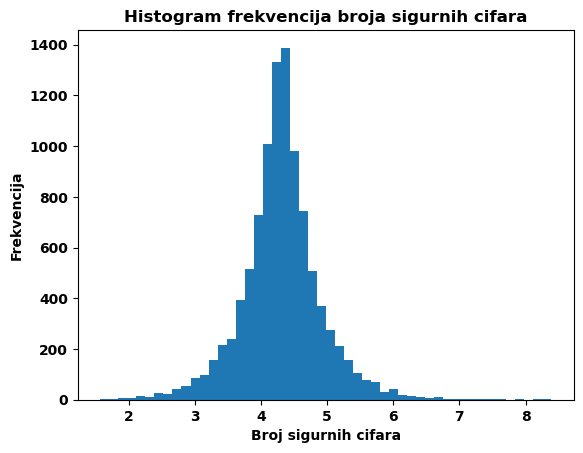

In [7]:
x_true = rndm.uniform(0.1, 100, 10_000)
x_approx = np.round(x_true, 2)
relativna_greska = np.abs(x_approx - x_true) / np.abs(x_true)
sigurne_cifre = -np.log10(relativna_greska)

plt.hist(sigurne_cifre, bins=50)
plt.xlabel("Broj sigurnih cifara")
plt.ylabel("Frekvencija")
plt.title("Histogram frekvencija broja sigurnih cifara")
plt.show()

Sa histograma se može videti da iako su svi brojevi zaokruženi na isti broj decimala, nemaju svi isti broj sigurnih cifara. Razlog za to je što nisu iste relativne greške kod svih brojeva: veće vrednosti imaju manje relativne greške pri istom zaokruživanju. Kako broj sigurnih cifara zavisi od relativne greške, tako nemaju svi brojevi isti broj sigurnih cifara.

<div class="alert alert-block alert-info">
<b>10/10 поена </b> 
</div>

***

**Задатак 4.** Посматрајмо функцију $f(x)$ дефинисану изразом:

$$ f(x) = \frac{x - \sin x}{x^3} $$

Теоријска гранична вредност ове функције када $x \to 0$ износи $\dfrac{1}{6}$. Међутим, приликом имплементације на рачунару коришћењем стандардних типова података са покретним зарезом, долази до значајног губитка тачности за мале вредности аргумента услед феномена **губитка значајних цифара** или **катрастрофалног поништавања** (*catastrophic cancellation*).

Циљ овог задатка је анализа нумеричке нестабилности, утицаја типа података (`dtype`) и имплементација робустног, потпуно векторизованог решења.

### Захтеви задатка

#### 1. Анализа нестабилности и типова података
Написати Python функцију `naive_f(x)` која за улаз има `numpy` низ и директно примењује дату формулу $ f(x) = \dfrac{x - \sin x}{x^3} $.
*   Генерисати низ вредности $x$ у интервалу $[10^{-8}, 1]$ (логаритамска скала).
*   Израчунати вредности функције користећи два различита типа података:
    *   **Single precision:** `np.float32`
    *   **Double precision:** `np.float64`
*   Графички приказати резултате оба израчунавања на истом дијаграму (користити `semilogx` или `loglog`).
*   **Питање:** За које вредности $x$ (отприлике) сигнал постаје чист шум за `float32`, а за које за `float64`?

(5 поена)

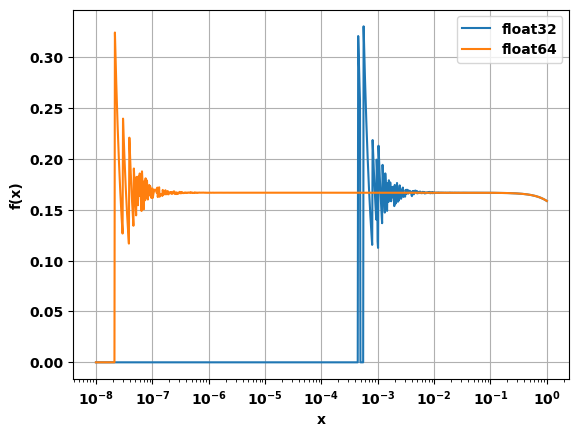

In [8]:
def naive_f(x):
    return (x - np.sin(x)) / x**3

x32 = np.logspace(-8, 0, 1000, dtype=np.float32)
y32 = naive_f(x32)

x64 = np.logspace(-8, 0, 1000, dtype=np.float64)
y64 = naive_f(x64)

plt.figure()
plt.semilogx(x32, y32, label="float32")
plt.semilogx(x64, y64, label="float64")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()
plt.grid(True)
plt.show()

Kada se koristi `np.float32` tip, signal počinje da bude šum otprilike negde oko $5 \times 10^{-3}$. Za vrednosti manje od toga, signal postaje šum.

Kada se koristi `np.float64` tip, signal počinje da bude šum otprilike negde oko $3 \times 10^{-7}$. Za vrednosti manje od toga, signal postaje šum. Može se primetiti da `np.float64` tip omogućava da granica šuma bude još manja vrednost u poređenju sa `np.float32` tipom, što je i očekivano jer ima veću preciznost.

<div class="alert alert-block alert-info">
<b>5/5 поена </b> 
</div>

#### 2. Математичка стабилизација (Тејлоров развој)
У текстуалном извештају (Markdown ћелији):
*   Развити функцију $\sin x$ у Маклоренов ред.
*   Извести апроксимацију функције $f(x)$ задржавајући прва три ненулта члана реда.
*   Проценити ред величине грешке одсецања ($\mathcal{O}(x^n)$) ако користимо ову апроксимацију.

(10 поена)

Maklorenov red je poseban slučaj Tejlorovog reda, gde se razvoj funkcije vrši oko tačke $0$:

$$
f(x) = f(0) + f'(0)\,x + \frac{f''(0)}{2!}\,x^2 + \frac{f^{(3)}(0)}{3!}\,x^3 + \cdots + \frac{f^{(n)}(0)}{n!}\,x^n + \cdots
$$

Ovu formulu je potrebno primeniti na funkciju $f(x) = \sin x$. Najpre se izračunavaju izvodi i njihove vrednosti u tački $x = 0$:

$$
\begin{aligned}
f(x) &= \sin x, \\[4pt]
f'(x) &= \cos x, & f'(0) &= 1, \\[4pt]
f''(x) &= -\sin x, & f''(0) &= 0, \\[4pt]
f^{(3)}(x) &= -\cos x, & f^{(3)}(0) &= -1, \\[4pt]
f^{(4)}(x) &= \sin x, & f^{(4)}(0) &= 0.
\end{aligned}
$$

Može se uočiti da se izvodi periodično ponavljaju sa periodom $4$, kao i da svi parni izvodi u tački $0$ imaju vrednost $0$, dok su neparni izvodi naizmenično $1$ i $-1$.

Ubacivanjem ovih vrednosti u Maklorenov red dobijamo:

$$
\sin x = 0 + 1\cdot x + 0\cdot \frac{x^2}{2!}
- 1\cdot \frac{x^3}{3!}
+ 0\cdot \frac{x^4}{4!}
+ 1\cdot \frac{x^5}{5!}
+ 0\cdot \frac{x^6}{6!}
- 1\cdot \frac{x^7}{7!}
+ \cdots
$$

Sređeni oblik je:

$$
\sin x = x - \frac{x^3}{3!} + \frac{x^5}{5!} - \frac{x^7}{7!} + \mathcal{O}(x^9).
$$


Aproksimacija funkcije $\sin x$ sa prva tri nenulta člana reda je:

$$
\sin x \approx x - \frac{x^3}{6} + \frac{x^5}{120}.
$$

***

Ubacujemo ovu aproksimaciju u izraz za $f(x)$:

$$
f(x) = \frac{x - \sin x}{x^3}
\approx \frac{x - \left( x - \frac{x^3}{6} + \frac{x^5}{120} \right)}{x^3}.
$$

Sređivanjem brojioca dobijamo:

$$
x - x + \frac{x^3}{6} - \frac{x^5}{120}
= \frac{x^3}{6} - \frac{x^5}{120}.
$$

Zatimo delimo sa $x^3$:

$$
f(x) \approx \frac{\frac{x^3}{6} - \frac{x^5}{120}}{x^3}
= \frac{1}{6} - \frac{x^2}{120}.
$$

Konačno, aproksimacija funkcije je:

$$
f(x) \approx \frac{1}{6} - \frac{x^2}{120}
$$

***

Kako bismo odredili red veličine greške odsecanja potrebno je da vidimo koji je sledeći član u Maklorenovom razvoju funkcije $\sin x$. To je:

$$
- \frac{x^7}{7!} = -\frac{x^7}{5040}.
$$

Da je i ovaj član bio uključen u aproksimaciju funkcije $f(x)$, ta aproksimacija bi bila $$f(x) \approx \frac{1}{6} - \frac{x^2}{120} + \frac{x^4}{5040}$$

S obzirom na to da je stepen poslednjeg člana jednak $4$ (prvi član koji nije uključen u aproksimaciju), to red veličine greške odsecanja za aproksimaciju funkcije $f(x)$ iznosi $\mathcal{O}(x^4).$

<div class="alert alert-block alert-info">
<b>10/10 поена </b> 
</div>

#### 3. Векторизована имплементација (`stable_f`)
Написати функцију `stable_f(x)` која обезбеђује максималну тачност за све вредности $x$.
**Стриктна ограничења имплементације:**
*   Функција мора да прихвата `numpy` низ произвољне димензије.
*   **ЗАБРАЊЕНО је коришћење петљи (`for`, `while`, `list comprehensions`).** Решење мора бити потпуно векторизовано.
*   Код мора аутоматски детектовати елементе низа за које је директна формула нестабилна и на њих применити Тејлорову апроксимацију. Остали елементи се рачунају директно.
*   Користити `numpy` механизме: `boolean masking` (препоручено) или `np.where`.
*   Граничну вредност ($\epsilon$) за прелазак са једне методе на другу одредити динамички, на основу машинске тачности за дати тип података (видети: `np.finfo(dtype).eps`), тако да грешка апроксимације буде занемарљива.

(10 поена)

Da bi greška aproksimacije bila zanemarljiva, potrebno je da ona bude manja od mašinske tačnosti ($\epsilon$). Pošto član $\frac{x^4}{5040}$ nije uključen u aproksimaciju funkcije i on predstavlja grešku, on treba da bude manji od $\epsilon$. Rešavanjem nejednakosti 
$$
\frac{x^4}{5040} \lesssim \epsilon
$$ 
dobija se dinamička granica $x_{\text{g}}$. Za vrednosti koje su po apsolutnoj vrednosti manje od granice $x_{\text{g}}$ koristimo Tejlorov razvoj, a za one koje su veće koristimo originalnu formulu za funkciju. Na ovaj način je obezbeđeno da greška aproksimacije bude zanemarljiva u odnosu na mašinsku tačnost.


In [9]:
def stable_f(x):
    eps = np.finfo(x.dtype).eps

    # dinamicko odredjivanje granicne vrednosti za prelazak sa jedne metode na drugu
    xg = (5040*eps) ** 0.25

    # kreiranje boolean maske
    koristi_aproks = np.abs(x) < xg
    
    f = np.empty_like(x, dtype=x.dtype)

    # aproksimacija za vrednosti bliske nuli
    f[koristi_aproks] = 1/6 - x[koristi_aproks]**2 / 120
    # originalni izraz za preostale vrednosti
    f[~koristi_aproks] = (x[~koristi_aproks] - np.sin(x[~koristi_aproks])) / x[~koristi_aproks]**3
    
    return f

<div class="alert alert-block alert-info">
<b>10/10 поена </b> 
</div>

#### 4. Анализа релативне грешке
*   Као референтну ("тачну") вредност користити резултат добијен помоћу `stable_f` над типом `np.float64` (или `mpmath` библиотеком ако желите већу прецизност).
*   Израчунати и графички приказати **релативну грешку** наивног приступа у односу на стабилни приступ на Log-Log дијаграму.

(5 поена)

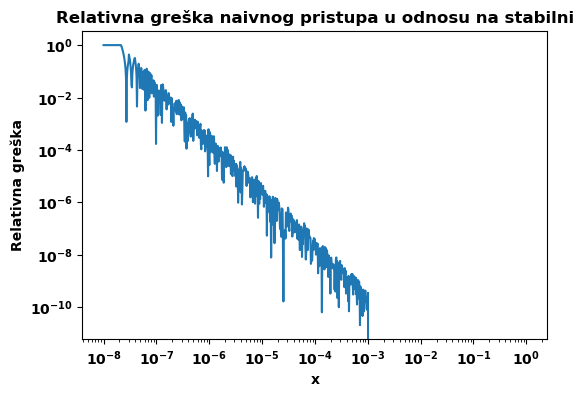

In [10]:
x = np.logspace(-8, 0, 1000, dtype=np.float64)
f_ref = stable_f(x)
f_naive = naive_f(x)

rel_greska = np.abs(f_naive - f_ref) / np.abs(f_ref)

plt.figure(figsize=(6,4))
plt.loglog(x, rel_greska)
plt.xlabel('x')
plt.ylabel('Relativna greška')
plt.title('Relativna greška naivnog pristupa u odnosu na stabilni')
plt.show()

<div class="alert alert-block alert-info">
<b>5/5 поена </b> 
</div>

### Напомене за израду

*   Посебну пажњу обратити на *Broadcasting* правила у NumPy-у.
*   Код који користи `np.where` може генерисати *RuntimeWarning* (дељење нулом) чак и ако се ти резултати касније одбацују. Идеално решење треба или да сузбије ова упозорења (`np.errstate`) или да користи маскирање тако да се "опасне" операције никада не изврше над нулама.
*   Решење треба да буде ефикасно и за веома велике низове ($N > 10^6$).

***

**Задатак 5.** Ретко поседнуте матрице представљају оне које имају велики садржај нула елемената.

**Дефиниција 1.** (Вилкинсон): Матрица може да се сматра ретко поседнутом када се ненула елементи налазе или концентрисано у уском појасу око дијагонале, или су распоређени на мање систематичан начин. Матрицу ћемо називати густом ако проценат нула-елемената или њихова расподела није таква да је економично искористити њихово присуство.

**Дефиниција 2.** Матрица $A\in\mathcal{M}_{m\times n}$ је ретко поседнута уколико је број ненула елемената $\mathcal{O}(m+n).$

У наредној кодној ћелији је дефинисана класа `RetkaMatrica` која имплементира тзв. **COO (Coordinate)** формат. Она има следеће карактеристике:
- `m`: број врста.
- `n`: број колона.
- `data`: NumPy низ димензије $k\times3$ који садржи податке о свим ненула елементима у облику `[vrednost, i, j]`.
- `k`: укупан број ненула елемената.
- `vrste` и `kolone`: помоћни низови индекса врста и колона које садрже податке.

Приликом иницијализације, класа аутоматски сортира елементе лексикографски (по врстама, па по колонама) и сабира вредности ако се појаве дупликати на истим координатама.

In [2]:
class RetkaMatrica:
    def __init__(self, m, n, entries=None):
        """
        m: broj vrsta
        n: broj kolona
        entries: numpy niz dimenzije k x 3, gde je svaki red oblika [vrednost, i, j]
        """
        self.m = m
        self.n = n
        if entries is None:
            self.data = np.zeros((0, 3))
        else:
            self.data = np.array(entries, dtype=float)
            self._ukloni_duplikate()
            
    def _ukloni_duplikate(self):
        """
        Лексикографски сортира по (i, j) и сабира све вредности на истим позицијама.
        Задржава само по један елемент по индексу (i, j), уз збир као вредност.
        """
        if len(self.data) == 0:
            self.k = 0
            self.vrste = np.array([])
            self.kolone = np.array([])
            return

        i = self.data[:, 1].astype(int)
        j = self.data[:, 2].astype(int)

        # Лексикографско сортирање (прво по i, па по j)
        # np.lexsort користи последњи аргумент као примарни кључ
        sort_idx = np.lexsort((j, i))
        self.data = self.data[sort_idx]

        # Креирање јединствених 1D кључева за индексе (flattening)
        kljucevi = self.data[:, 1].astype(int) * self.n + self.data[:, 2].astype(int)
        
        # Проналажење граница група истих кључева
        _, start_idx = np.unique(kljucevi, return_index=True)

        # Сабирање вредности по групама (користимо reduceat за брзину)
        vrednosti = self.data[:, 0]
        zbir = np.add.reduceat(vrednosti, start_idx)

        # Реконструисање i и j из кључева (за позиције где су сабране вредности)
        # Узимамо само индексе на почецима група јер су унутар групе исти
        rekonstruisani_kljucevi = kljucevi[start_idx]
        novi_i = rekonstruisani_kljucevi // self.n
        novi_j = rekonstruisani_kljucevi % self.n

        # Нови садржај data
        self.data = np.column_stack((zbir, novi_i, novi_j))

        # Ажурирање атрибута
        self.vrste = np.unique(novi_i)
        self.kolone = np.unique(novi_j)
        self.k = len(self.data)

    def __repr__(self):
        return f"RetkaMatrica({self.m}x{self.n}) sa {self.k} nenula elemenata \n{self.data}"

    def puna_matrica(self):
        """Vraća gustu matricu (numpy array) za potrebe provere."""
        dense = np.zeros((self.m, self.n))
        if self.k > 0:
            dense[self.data[:,1].astype(int), self.data[:,2].astype(int)] = self.data[:,0]
        return dense

Показаћемо функционалности класе на примеру. 

Дефинишемо матрицу димензије $5\times3$ која на позицији (0,0) има вредност 1, на позицији (2,1) има вредност 5, итд.

In [3]:
A=RetkaMatrica(5,3,[[1,0,0],[5,2,1],[-3,1,2],[-2,1,2],[-1,0,1],[1,4,2]])
A

RetkaMatrica(5x3) sa 5 nenula elemenata 
[[ 1.  0.  0.]
 [-1.  0.  1.]
 [-5.  1.  2.]
 [ 5.  2.  1.]
 [ 1.  4.  2.]]

Низ ненула елемената је смањен са 6 на 5 због поновљеног пара индекса (1,2). Вредности -3 и -2 на тој позицији су сабране. 

Изглед пуне матрице, тј. када се допуни нулама даје наредни метод:

In [4]:
A.puna_matrica()

array([[ 1., -1.,  0.],
       [ 0.,  0., -5.],
       [ 0.,  5.,  0.],
       [ 0.,  0.,  0.],
       [ 0.,  0.,  1.]])

Унети подаци о ненула елеменатима су садржај атрибута `data`.

In [5]:
A.data   #primecujemo leksikografsko uredjenje vrsta, kolona iako nisu tako uneti podaci o samoj matrici

array([[ 1.,  0.,  0.],
       [-1.,  0.,  1.],
       [-5.,  1.,  2.],
       [ 5.,  2.,  1.],
       [ 1.,  4.,  2.]])

Вредности појединачних елемената можемо прочитати индексирањем.

In [15]:
A.data[:,0]

array([ 1., -1., -5.,  5.,  1.])

Одговарајући индекси врста и колона се такође добијају индексирањем.

In [16]:
A.data[:,1], A.data[:,2]

(array([0., 0., 1., 2., 4.]), array([0., 1., 2., 1., 2.]))

Поред тога, о ретко поседнутој матрици можемо сазнати редукован низ индекса врста и низ индекса колона на чијим позицијама има ненула елемената, као и сам број ненула елемената кроз додатне атрибуте.

In [17]:
A.vrste, A.kolone, A.m, A.n, A.k

(array([0, 1, 2, 4]), array([0, 1, 2]), 5, 3, 5)

Појединачним елементима можемо да приступимо индексирањем. Рецимо ненула елементи врсте са индексом 0.

In [18]:
maska=A.data[:, 1].astype(int) == 0
maska

array([ True,  True, False, False, False])

In [19]:
A.data[maska][:,0]

array([ 1., -1.])

Или индекси колона у којима се налазе ти ненула елементи врсте са индексом 1.

In [20]:
A.data[maska][:,2]

array([0., 1.])

In [21]:
A.data[maska]

array([[ 1.,  0.,  0.],
       [-1.,  0.,  1.]])

Циљ овог задатка је имплементација ефикасног множења матрица коришћењем NumPy механизама за векторизацију, без употребе експлицитних петљи, или што мање њих.

**а)** Множење ретко поседнуте матрице и густог вектора 

Написати функцију (или метод класе) који рачуна производ $y = A \cdot x$, где је:
*   $A$: објекат класе `RetkaMatrica` димензије $m \times n$.
*   $x$: густи NumPy низ (вектор) димензије $n$.

**Захтеви:**
1.  Користити што више уграђену функционалност NumPy низова (нпр. `bincount`, `add.at`, fancy indexing).
2.  **Строго забрањено** претварање ретке матрице у пуну (`puna_matrica()`) ради множења. Може за проверу резултата.
3.  **Забрањено** коришћење `for` или `while` петљи за пролазак кроз елементе.

(10 поена)

In [6]:
def mnozenje_gustim_vektorom(A, x):
    # mesto za rezultat
    y = np.zeros(A.m)
    
    vrednosti = A.data[:, 0] 
    i = A.data[:, 1].astype(int) # vrste
    j = A.data[:, 2].astype(int) # kolone

    # kolona (j) u kojoj se element nalazi u matrici odredjuje
    # sa kojim elementom vektora ce se taj element mnoziti
    # ideja je da se svaki nenula element matrice pomnozi sa elementom vektora
    # koji ima isti indeks kao kolona tog elementa matrice
    # cime se dobija vektor duzine k (k je ukupan broj nenula elemenata u matrici)
    proizvod = vrednosti * x[j]

    # nakon sto je dobijen vektor duzine k,
    # potrebno je redukovati ga na vektor duzine m (broj vrsta matrice)
    # tako sto se saberu dobijeni proizvodi koji imaju isti indeks vrste
    np.add.at(y, i, proizvod)

    return y

<div class="alert alert-block alert-info">
<b>10/10 поена </b> 
    
недостаје провера да ли је множење могуће спровести, тј. да ли је вектор одговарајуће димензије.
</div>

In [7]:
v=np.array([1,-1,1.])
mnozenje_gustim_vektorom(A, v)

array([ 2., -5., -5.,  0.,  1.])

In [8]:
A.puna_matrica()@v

array([ 2., -5., -5.,  0.,  1.])

**б)** Множење ретко поседнуте матрице и ретког вектора 

Написати функцију (или метод класе) који рачуна производ $y = A \cdot v$, где је:
*   $A$: објекат класе `RetkaMatrica` димензије $m \times n$.
*   $v$: објекат класе `RetkaMatrica` који представља вектор колону димензије $n \times 1$.

**Напомена:** Ретки вектор се овде третира као ретка матрица где је друга димензија 1 (индекс колоне је увек 0).

**Захтеви:**
1.  Реализовати множење налажењем пресека индекса (колоне матрице $A$ морају одговарати врстама вектора $v$).
2.  Користити NumPy скуповне операције (нпр. `isin`, `searchsorted` или логичко маскирање).
3.  Резултат може бити густи NumPy низ.
4.  Није дозвољено конвертовање у густе структуре пре самог израчунавања.  Може за проверу резултата.

(10 поена)

In [10]:
def mnozenje_retkim_vektorom(A, v):
    # mesto za rezultat
    y = np.zeros(A.m)

    v_i = v.data[:, 1].astype(int)  # vrste nenula elemenata vektora
    v_vrednosti = v.data[:, 0] # nenula elementi vektora
    
    # za razliku od primera pod a) gde su svi nenula elementi
    # matrice mnozeni odgovarajucim elementima vektora
    # ovde je potrebno odrediti koji od nenula elemenata
    # matrice imaju odgovarajuci nenula element za mnozenje u vektoru
    # kako se ne bi obavljala nepotrebna izracunavanja
    maska = np.isin(A.data[:, 2].astype(int), v_i)
    
    # izdvajamo samo one nenula elemente matrice koji imaju odgovarajući nenula element u vektoru
    A_data_filtered = A.data[maska]

    # ako nema preseka rezultat je vektor sa svim nulama
    if len(A_data_filtered) == 0:
        return y

    vrednosti = A_data_filtered[:, 0]
    i = A_data_filtered[:, 1].astype(int) # vrste
    j = A_data_filtered[:, 2].astype(int) # kolone

    # nije moguce jednostavno pomnoziti nenula elemente matrice
    # sa elementima vektora jer vektor nije gust vec je zapamcen kao RetkaMatrica
    # zbog toga je potrebno odrediti za svaki nenula element u A
    # koji element retko posednutog vektora mu odgovara za mnozenje
    indices = np.searchsorted(v_i, j)
    
    # na kraju se mnoze odgovarajuci elementi i akumuliraju se u rezultujuci vektor
    # po istom principu kao pod a)
    proizvod = vrednosti * v_vrednosti[indices]
    np.add.at(y, i, proizvod)
    
    return y

<div class="alert alert-block alert-info">
<b>10/10 поена </b> 
    
недостаје провера да ли је множење могуће спровести, тј. да ли је вектор одговарајуће димензије.
</div>

In [11]:
u=RetkaMatrica(3,1,[[1,0,0],[-1,0,1]])
mnozenje_retkim_vektorom(A, u)

array([ 2.,  0., -5.,  0.,  0.])

In [13]:
A.puna_matrica()@u.puna_matrica()

array([[ 2.],
       [ 0.],
       [-5.],
       [ 0.],
       [ 0.]])

***

<div class="alert alert-block alert-info">
<b>Укупно 85/85 поена </b>
</div>

***